# 17-720 HW4 Part 2: Finetuning InceptionV3 on DermaMNIST — Shawn Xiang

This notebook finetunes an ImageNet-pretrained **InceptionV3** on **DermaMNIST**, a 7-class skin-lesion
dataset derived from HAM10000 (ISIC 2018). InceptionV3 is the architecture Esteva et al. (Nature 2017)
finetuned for dermatologist-level skin cancer classification, so this is a small-scale version of that setup.

Two transfer strategies are compared on the official MedMNIST train/validation/test split:

* **Experiment A, linear probe:** frozen ImageNet backbone, new linear classifier on the 2048-d pooled features.
* **Experiment B, full finetuning:** all layers trained, with a 10x lower learning rate on the pretrained backbone than on the new heads.

Both use a class-weighted cross-entropy loss to address class imbalance. The checkpoint (epoch) is selected on the
validation split by balanced accuracy, and the test split is evaluated once per experiment.

**Run in Colab:** Runtime > Change runtime type > GPU, then Run all. The same notebook runs locally (CUDA, Apple MPS or CPU).
All numbers and figures shown below come from the execution recorded in this file; the run-information cell states the hardware.

In [1]:
# Colab: installs medmnist. Locally: skipped when medmnist is already installed.
import importlib.util
if importlib.util.find_spec("medmnist") is None:
    %pip install -q medmnist

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy, json, os, platform, random, subprocess, time
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import medmnist
from medmnist import DermaMNIST
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support, roc_auc_score, roc_curve)

# ---------------- configuration ----------------
QUICK_TEST = False     # True = tiny subsets and 1 epoch, only to check the code path
SEED = 42
IMG_SIZE = 224                  # largest MedMNIST+ resolution
INPUT_SIZE = 299                # InceptionV3 native input size
PROBE_EPOCHS = 100 # Experiment A (linear probe on cached features)
PROBE_LR = 1e-3
PROBE_BATCH = 256
FT_EPOCHS = 10       # Experiment B (full finetuning)
FT_BATCH = 32
FT_LR_BACKBONE = 1e-4
FT_LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-4
AUX_WEIGHT = 0.4                # weight of the auxiliary-classifier loss during training
OUT_DIR = "."                   # figures and Part2-Results.json are written here (relative path)

if QUICK_TEST:
    PROBE_EPOCHS, FT_EPOCHS = 2, 1

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
CLASS_SHORT = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_LONG = ["actinic keratoses / intraepithelial carcinoma", "basal cell carcinoma",
              "benign keratosis-like lesions", "dermatofibroma", "melanoma",
              "melanocytic nevi", "vascular lesions"]
MEL = CLASS_SHORT.index("mel")
print("QUICK_TEST =", QUICK_TEST)

QUICK_TEST = False


In [3]:
# ---------------- device and run information ----------------
if torch.cuda.is_available():
    device = torch.device("cuda")
    hw = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    try:
        hw = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True,
                            text=True).stdout.strip() + " (Apple MPS GPU)"
    except Exception:
        hw = "Apple Silicon (MPS)"
else:
    device = torch.device("cpu")
    hw = platform.processor() or "CPU"

RUN_INFO = {
    "run_started_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
    "device": device.type,
    "hardware": hw,
    "platform": platform.platform(),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "medmnist": medmnist.__version__,
}
for k, v in RUN_INFO.items():
    print(f"{k:16s} {v}")

run_started_utc  2026-10-29 08:23 UTC
device           cuda
hardware         Tesla T4
platform         Linux-6.18.55+-x86_64-with-glibc2.39
python           3.13.15
torch            2.11.0+cu128
torchvision      0.26.0+cu128
medmnist         3.0.2


## 1. Data: DermaMNIST (MedMNIST v2, 224 x 224)

DermaMNIST contains 10,015 dermatoscopic images from HAM10000 in 7 diagnostic classes, with an official 7:1:2
train/validation/test split. We use the 224 x 224 version (the largest MedMNIST+ size); the original HAM10000
images are 600 x 450. The whole split is held in memory as uint8 and preprocessed on the GPU in batches.

In [4]:
import contextlib, io
with contextlib.redirect_stderr(io.StringIO()):   # hide the ~1 GB download progress bar
    splits = {s: DermaMNIST(split=s, size=IMG_SIZE, download=True) for s in ["train", "val", "test"]}
X, Y = {}, {}
for s, ds in splits.items():
    X[s] = torch.from_numpy(ds.imgs)                         # (N, 224, 224, 3) uint8
    Y[s] = torch.from_numpy(ds.labels.reshape(-1).astype(np.int64))
if QUICK_TEST:
    g = torch.Generator().manual_seed(SEED)
    for s, n in [("train", 256), ("val", 128), ("test", 128)]:
        idx = torch.randperm(len(Y[s]), generator=g)[:n]
        X[s], Y[s] = X[s][idx], Y[s][idx]

N_CLASSES = len(CLASS_SHORT)
counts = {s: np.bincount(Y[s].numpy(), minlength=N_CLASSES) for s in X}
print("image tensor shape (train):", tuple(X["train"].shape))
print(f"{'class':6s} {'train':>6s} {'val':>5s} {'test':>5s}  description")
for c in range(N_CLASSES):
    print(f"{CLASS_SHORT[c]:6s} {counts['train'][c]:6d} {counts['val'][c]:5d} {counts['test'][c]:5d}  {CLASS_LONG[c]}")
print(f"{'total':6s} {len(Y['train']):6d} {len(Y['val']):5d} {len(Y['test']):5d}")

# Class weights for the loss: w_c = N / (K * n_c)  (inverse class frequency on the training split)
class_weights = torch.tensor(len(Y["train"]) / (N_CLASSES * np.maximum(counts["train"], 1)), dtype=torch.float32)
print("\nclass weights:", {c: round(float(w), 2) for c, w in zip(CLASS_SHORT, class_weights)})

image tensor shape (train): (7007, 224, 224, 3)
class   train   val  test  description
akiec     228    33    66  actinic keratoses / intraepithelial carcinoma
bcc       359    52   103  basal cell carcinoma
bkl       769   110   220  benign keratosis-like lesions
df         80    12    23  dermatofibroma
mel       779   111   223  melanoma
nv       4693   671  1341  melanocytic nevi
vasc       99    14    29  vascular lesions
total    7007  1003  2005

class weights: {'akiec': 4.39, 'bcc': 2.79, 'bkl': 1.3, 'df': 12.51, 'mel': 1.28, 'nv': 0.21, 'vasc': 10.11}


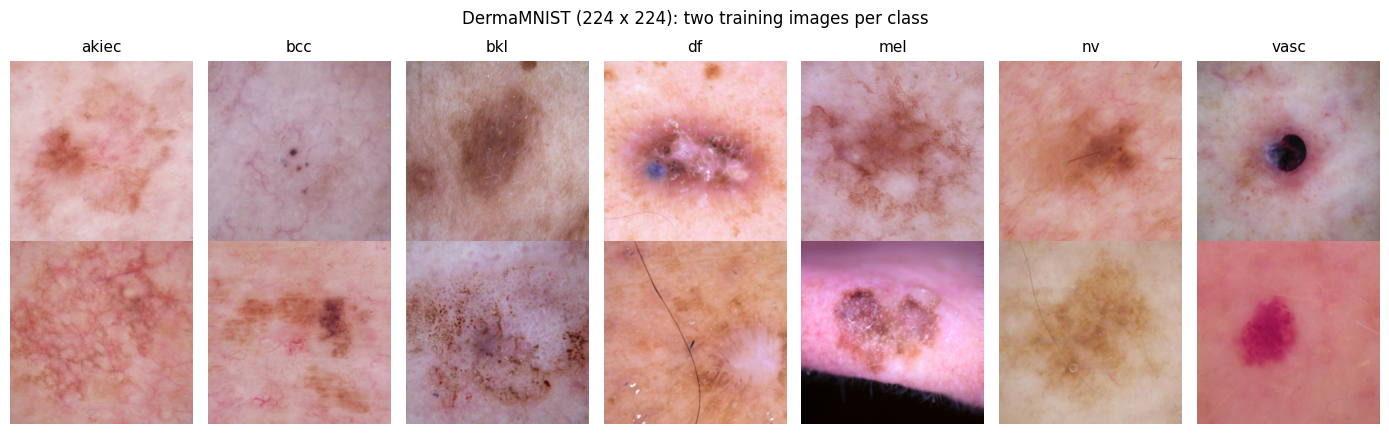

In [5]:
fig, axes = plt.subplots(2, N_CLASSES, figsize=(14, 4.4))
rng = np.random.default_rng(SEED)
for c in range(N_CLASSES):
    idx = rng.choice(np.where(Y["train"].numpy() == c)[0], size=2, replace=False)
    for r in range(2):
        axes[r, c].imshow(X["train"][idx[r]].numpy())
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASS_SHORT[c], fontsize=11)
fig.suptitle("DermaMNIST (224 x 224): two training images per class", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part2_sample_images.png"), dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# ---------------- GPU preprocessing and augmentation ----------------
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def preprocess(xb, train=False):
    # uint8 (B,H,W,3) -> ImageNet-normalized float (B,3,299,299) on device.
    x = xb.to(device).permute(0, 3, 1, 2).float().div_(255.0)
    if train:
        B = x.shape[0]
        def coin():
            return (torch.rand(B, device=device) < 0.5).view(B, 1, 1, 1)
        # Dermoscopy has no canonical orientation: random flips + transpose cover all 8 dihedral symmetries.
        x = torch.where(coin(), x.flip(3), x)
        x = torch.where(coin(), x.flip(2), x)
        x = torch.where(coin(), x.transpose(2, 3), x)
        # Mild brightness/contrast jitter (+-10%).
        b = 1 + (torch.rand(B, 1, 1, 1, device=device) - 0.5) * 0.2
        c = 1 + (torch.rand(B, 1, 1, 1, device=device) - 0.5) * 0.2
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (((x - m) * c + m) * b).clamp_(0, 1)
    x = F.interpolate(x, size=(INPUT_SIZE, INPUT_SIZE), mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

def build_inception(n_classes):
    # ImageNet-pretrained InceptionV3. torchvision sets transform_input=True for these weights, which maps
    # ImageNet-normalized input to the [-1, 1] scaling the original Google weights expect.
    with contextlib.redirect_stderr(io.StringIO()):   # hide the weight-download progress bar
        m = torchvision.models.inception_v3(weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, n_classes)                          # main head: 2048 -> 7
    m.AuxLogits.fc = nn.Linear(m.AuxLogits.fc.in_features, n_classes)      # auxiliary head: 768 -> 7
    return m

@torch.no_grad()
def predict_logits(model, Xs, bs=64):
    model.eval()
    out = []
    for i in range(0, len(Xs), bs):
        out.append(model(preprocess(Xs[i:i + bs])).float().cpu())
    return torch.cat(out)

def compute_metrics(y, prob):
    y = np.asarray(y); prob = np.asarray(prob)
    pred = prob.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(N_CLASSES), zero_division=0)
    try:
        macro_auc = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(N_CLASSES)))
    except ValueError:            # a class missing from y (only possible with QUICK_TEST subsets)
        macro_auc = float("nan")
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "macro_auc_ovr": macro_auc,
        "macro_f1": f1_score(y, pred, average="macro", labels=list(range(N_CLASSES)), zero_division=0),
        "melanoma_vs_rest_auc": roc_auc_score(y == MEL, prob[:, MEL]) if 0 < (y == MEL).sum() < len(y) else float("nan"),
        "per_class": {CLASS_SHORT[c]: {"precision": p[c], "recall": r[c], "f1": f[c], "support": int(s[c]),
                                       "auc_ovr": roc_auc_score(y == c, prob[:, c]) if 0 < (y == c).sum() < len(y) else float("nan")}
                      for c in range(N_CLASSES)},
        "confusion_matrix": confusion_matrix(y, pred, labels=range(N_CLASSES)).tolist(),
    }

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
print("preprocessed batch:", tuple(preprocess(X["train"][:2], train=True).shape))

preprocessed batch: (2, 3, 299, 299)


## 2. Experiment A: frozen backbone + linear head (linear probe)

The pretrained backbone is used as a fixed feature extractor: each image (no augmentation) is passed once through
InceptionV3 in eval mode and the 2048-d global-average-pooled features are cached. A new linear layer is then trained
on the cached training features with class-weighted cross-entropy (AdamW). The epoch with the best validation balanced
accuracy is kept.

In [7]:
seed_everything(SEED)
t0 = time.perf_counter()
backbone = build_inception(N_CLASSES)
backbone.fc = nn.Identity()          # output the 2048-d pooled features
backbone = backbone.to(device)
feats = {s: predict_logits(backbone, X[s], bs=64) for s in ["train", "val", "test"]}
t_extract = time.perf_counter() - t0
del backbone
print({s: tuple(v.shape) for s, v in feats.items()}, f"feature extraction: {t_extract:.1f} s")

seed_everything(SEED)
t0 = time.perf_counter()
probe = nn.Linear(2048, N_CLASSES).to(device)
opt = torch.optim.AdamW(probe.parameters(), lr=PROBE_LR, weight_decay=WEIGHT_DECAY)
Ftr, Ytr = feats["train"].to(device), Y["train"].to(device)
Fva, Yva = feats["val"].to(device), Y["val"].to(device)
hist_a = {"train_loss": [], "val_loss": [], "val_balanced_accuracy": [], "val_accuracy": []}
best_a = {"bal_acc": -1.0}
for ep in range(1, PROBE_EPOCHS + 1):
    probe.train()
    perm = torch.randperm(len(Ytr), device=device)
    tot = 0.0
    for i in range(0, len(perm), PROBE_BATCH):
        idx = perm[i:i + PROBE_BATCH]
        loss = criterion(probe(Ftr[idx]), Ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(idx)
    probe.eval()
    with torch.no_grad():
        lv = probe(Fva)
        vloss = criterion(lv, Yva).item()
    vpred = lv.argmax(1).cpu().numpy()
    vbal = balanced_accuracy_score(Y["val"].numpy(), vpred)
    hist_a["train_loss"].append(tot / len(Ytr)); hist_a["val_loss"].append(vloss)
    hist_a["val_balanced_accuracy"].append(vbal); hist_a["val_accuracy"].append(accuracy_score(Y["val"].numpy(), vpred))
    if vbal > best_a["bal_acc"]:
        best_a = {"bal_acc": vbal, "epoch": ep, "state": copy.deepcopy(probe.state_dict())}
    if ep == 1 or ep % 10 == 0 or ep == PROBE_EPOCHS:
        print(f"epoch {ep:3d}  train loss {hist_a['train_loss'][-1]:.4f}  val loss {vloss:.4f}  val bal-acc {vbal:.4f}")
t_probe = time.perf_counter() - t0
probe.load_state_dict(best_a["state"])
probe.eval()
with torch.no_grad():
    prob_a = {s: torch.softmax(probe(feats[s].to(device)), 1).cpu().numpy() for s in ["val", "test"]}
print(f"\nselected epoch {best_a['epoch']} (val balanced accuracy {best_a['bal_acc']:.4f}); probe training {t_probe:.1f} s")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


{'train': (7007, 2048), 'val': (1003, 2048), 'test': (2005, 2048)} feature extraction: 36.3 s


epoch   1  train loss 1.6825  val loss 1.4790  val bal-acc 0.4492


epoch  10  train loss 0.8932  val loss 1.1159  val bal-acc 0.5903


epoch  20  train loss 0.7164  val loss 1.0916  val bal-acc 0.5887


...

epoch  60  train loss 0.4526  val loss 1.1392  val bal-acc 0.5598


epoch  70  train loss 0.4213  val loss 1.1590  val bal-acc 0.5658


epoch  80  train loss 0.3928  val loss 1.1545  val bal-acc 0.5709


epoch  90  train loss 0.3707  val loss 1.1771  val bal-acc 0.5696


epoch 100  train loss 0.3476  val loss 1.2269  val bal-acc 0.5824

selected epoch 28 (val balanced accuracy 0.6146); probe training 3.5 s


## 3. Experiment B: full finetuning

All InceptionV3 weights are trained. The new main head (2048 -> 7) and auxiliary head (768 -> 7) use a learning rate of
1e-3 and the pretrained backbone uses 1e-4 (AdamW, weight decay 1e-4, one-cycle schedule with 10% warm-up). The training
loss is the class-weighted cross-entropy of the main output plus 0.4 x that of the auxiliary output, as in the original
InceptionV3 recipe; at evaluation time only the main output is used. Augmentation: random flips, transpose and mild
brightness/contrast jitter. Validation balanced accuracy is computed after every epoch and the best epoch is kept.

In [8]:
seed_everything(SEED)
model = build_inception(N_CLASSES).to(device)
head_params = list(model.fc.parameters()) + list(model.AuxLogits.fc.parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
opt = torch.optim.AdamW([{"params": backbone_params, "lr": FT_LR_BACKBONE},
                         {"params": head_params, "lr": FT_LR_HEAD}], weight_decay=WEIGHT_DECAY)
steps_per_epoch = (len(Y["train"]) + FT_BATCH - 1) // FT_BATCH
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[FT_LR_BACKBONE, FT_LR_HEAD],
                                            total_steps=FT_EPOCHS * steps_per_epoch, pct_start=0.1)
hist_b = {"train_loss": [], "val_loss": [], "val_balanced_accuracy": [], "val_accuracy": [], "epoch_seconds": []}
best_b = {"bal_acc": -1.0}
g = torch.Generator().manual_seed(SEED)
t_ft0 = time.perf_counter()
for ep in range(1, FT_EPOCHS + 1):
    te = time.perf_counter()
    model.train()
    perm = torch.randperm(len(Y["train"]), generator=g)
    tot, n = 0.0, 0
    for i in range(0, len(perm), FT_BATCH):
        idx = perm[i:i + FT_BATCH]
        if len(idx) < 2:                      # BatchNorm needs more than one sample in train mode
            continue
        xb, yb = preprocess(X["train"][idx], train=True), Y["train"][idx].to(device)
        out = model(xb)                       # InceptionOutputs(logits, aux_logits) in train mode
        loss_main = criterion(out.logits, yb)
        loss = loss_main + AUX_WEIGHT * criterion(out.aux_logits, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        tot += loss_main.item() * len(idx); n += len(idx)
    lv = predict_logits(model, X["val"])
    vloss = criterion(lv.to(device), Y["val"].to(device)).item()
    vpred = lv.argmax(1).numpy()
    vbal = balanced_accuracy_score(Y["val"].numpy(), vpred)
    hist_b["train_loss"].append(tot / n); hist_b["val_loss"].append(vloss)
    hist_b["val_balanced_accuracy"].append(vbal); hist_b["val_accuracy"].append(accuracy_score(Y["val"].numpy(), vpred))
    hist_b["epoch_seconds"].append(time.perf_counter() - te)
    if vbal > best_b["bal_acc"]:
        best_b = {"bal_acc": vbal, "epoch": ep,
                  "state": {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}}
    print(f"epoch {ep:2d}  train loss {tot / n:.4f}  val loss {vloss:.4f}  val acc {hist_b['val_accuracy'][-1]:.4f}  "
          f"val bal-acc {vbal:.4f}  ({hist_b['epoch_seconds'][-1]:.0f} s)", flush=True)
t_ft = time.perf_counter() - t_ft0
model.load_state_dict(best_b["state"])
prob_b = {s: torch.softmax(predict_logits(model, X[s]), 1).numpy() for s in ["val", "test"]}
print(f"\nselected epoch {best_b['epoch']} (val balanced accuracy {best_b['bal_acc']:.4f}); finetuning {t_ft / 60:.1f} min")

epoch  1  train loss 1.5658  val loss 1.0380  val acc 0.5623  val bal-acc 0.6270  (108 s)


epoch  2  train loss 0.8867  val loss 0.7536  val acc 0.6760  val bal-acc 0.7526  (112 s)


epoch  3  train loss 0.6750  val loss 0.7273  val acc 0.6800  val bal-acc 0.7372  (112 s)


epoch  4  train loss 0.5015  val loss 0.8372  val acc 0.7448  val bal-acc 0.7324  (112 s)


epoch  5  train loss 0.4009  val loss 0.6468  val acc 0.8046  val bal-acc 0.8073  (112 s)


...

epoch  7  train loss 0.2386  val loss 0.5658  val acc 0.8245  val bal-acc 0.8063  (112 s)


epoch  8  train loss 0.1952  val loss 0.5310  val acc 0.8504  val bal-acc 0.8306  (112 s)


epoch  9  train loss 0.1645  val loss 0.5856  val acc 0.8385  val bal-acc 0.8305  (112 s)


epoch 10  train loss 0.1521  val loss 0.5196  val acc 0.8475  val bal-acc 0.8409  (112 s)



selected epoch 10 (val balanced accuracy 0.8409); finetuning 18.6 min


## 4. Test-set evaluation

Each selected model is evaluated once on the official test split. The majority-class baseline always predicts
melanocytic nevi (the largest class) and gives every image the same score, so its AUC is 0.5.

In [9]:
y_test = Y["test"].numpy()
results = {
    "majority_baseline": compute_metrics(y_test, np.eye(N_CLASSES)[np.full(len(y_test), int(np.argmax(counts["train"])))]),
    "linear_probe": compute_metrics(y_test, prob_a["test"]),
    "full_finetune": compute_metrics(y_test, prob_b["test"]),
}
val_results = {"linear_probe": compute_metrics(Y["val"].numpy(), prob_a["val"]),
               "full_finetune": compute_metrics(Y["val"].numpy(), prob_b["val"])}
NAMES = {"majority_baseline": "Majority class (nv)", "linear_probe": "A: linear probe", "full_finetune": "B: full finetune"}
print(f"{'test split (n=' + str(len(y_test)) + ')':24s} {'accuracy':>9s} {'bal. acc':>9s} {'macro AUC':>10s} {'macro F1':>9s} {'mel AUC':>8s}")
for k, m in results.items():
    print(f"{NAMES[k]:24s} {m['accuracy']:9.3f} {m['balanced_accuracy']:9.3f} {m['macro_auc_ovr']:10.3f} "
          f"{m['macro_f1']:9.3f} {m['melanoma_vs_rest_auc']:8.3f}")
print("\nper-class test recall / precision")
print(f"{'class':6s} {'n':>5s} | {'A recall':>8s} {'A prec':>7s} {'A AUC':>6s} | {'B recall':>8s} {'B prec':>7s} {'B AUC':>6s}")
for c in CLASS_SHORT:
    a, b = results["linear_probe"]["per_class"][c], results["full_finetune"]["per_class"][c]
    print(f"{c:6s} {a['support']:5d} | {a['recall']:8.3f} {a['precision']:7.3f} {a['auc_ovr']:6.3f} | "
          f"{b['recall']:8.3f} {b['precision']:7.3f} {b['auc_ovr']:6.3f}")

test split (n=2005)       accuracy  bal. acc  macro AUC  macro F1  mel AUC
Majority class (nv)          0.669     0.143      0.500     0.115    0.500
A: linear probe              0.641     0.598      0.902     0.445    0.822
B: full finetune             0.857     0.841      0.980     0.788    0.951

per-class test recall / precision
class      n | A recall  A prec  A AUC | B recall  B prec  B AUC
akiec     66 |    0.667   0.254  0.923 |    0.773   0.708  0.984
bcc      103 |    0.583   0.432  0.942 |    0.845   0.784  0.991
bkl      220 |    0.400   0.524  0.865 |    0.805   0.725  0.971
df        23 |    0.522   0.128  0.887 |    0.870   0.625  0.989
mel      223 |    0.520   0.347  0.822 |    0.780   0.604  0.951
nv      1341 |    0.702   0.940  0.910 |    0.881   0.965  0.973
vasc      29 |    0.793   0.242  0.968 |    0.931   0.818  0.999


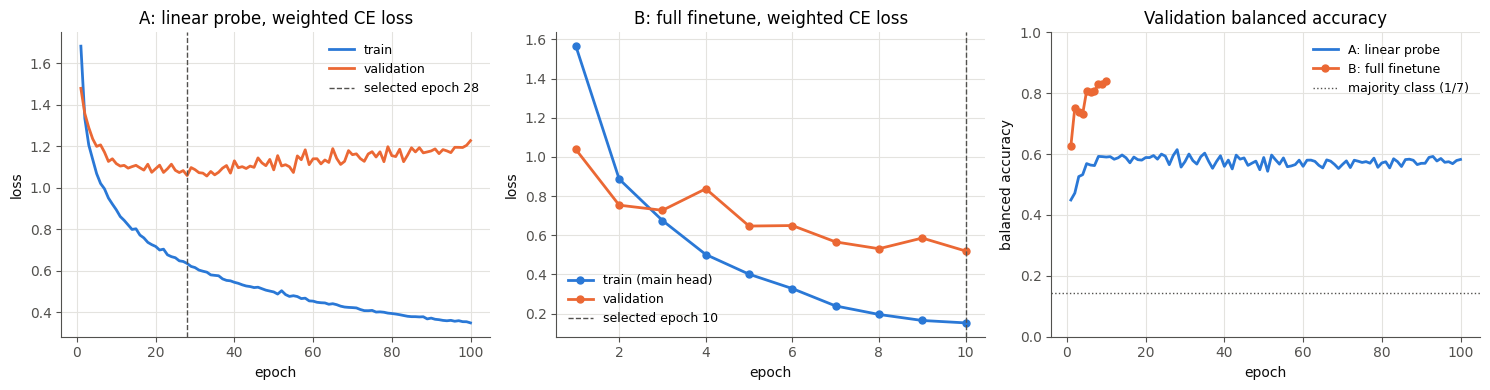

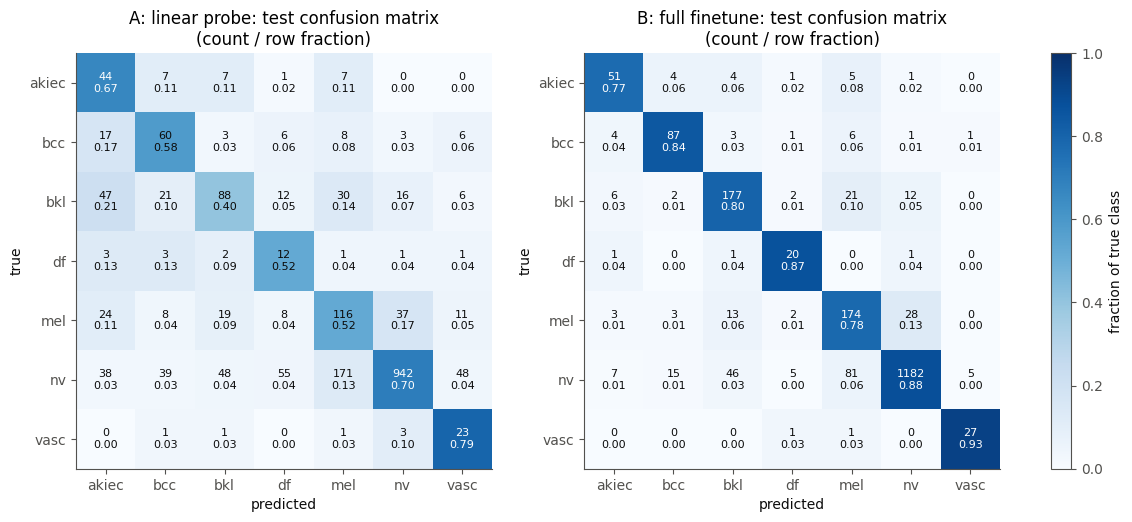

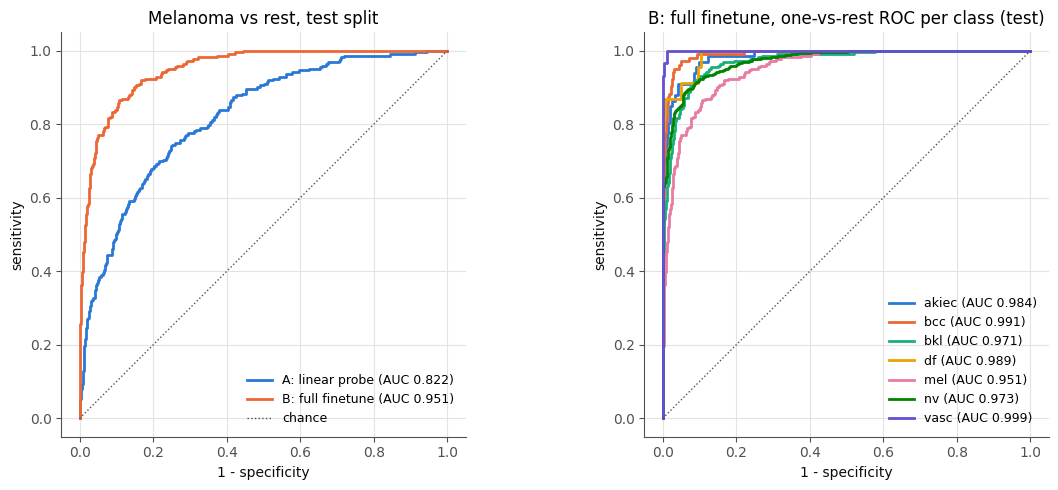

In [10]:
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8})

# Training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ea, eb = np.arange(1, len(hist_a["train_loss"]) + 1), np.arange(1, len(hist_b["train_loss"]) + 1)
axes[0].plot(ea, hist_a["train_loss"], color=BLUE, lw=2, label="train")
axes[0].plot(ea, hist_a["val_loss"], color=ORANGE, lw=2, label="validation")
axes[0].axvline(best_a["epoch"], color=MUTED, ls="--", lw=1, label=f"selected epoch {best_a['epoch']}")
axes[0].set(title="A: linear probe, weighted CE loss", xlabel="epoch", ylabel="loss")
axes[1].plot(eb, hist_b["train_loss"], color=BLUE, lw=2, marker="o", ms=5, label="train (main head)")
axes[1].plot(eb, hist_b["val_loss"], color=ORANGE, lw=2, marker="o", ms=5, label="validation")
axes[1].axvline(best_b["epoch"], color=MUTED, ls="--", lw=1, label=f"selected epoch {best_b['epoch']}")
axes[1].set(title="B: full finetune, weighted CE loss", xlabel="epoch", ylabel="loss")
axes[2].plot(ea, hist_a["val_balanced_accuracy"], color=BLUE, lw=2, label="A: linear probe")
axes[2].plot(eb, hist_b["val_balanced_accuracy"], color=ORANGE, lw=2, marker="o", ms=5, label="B: full finetune")
axes[2].axhline(1 / N_CLASSES, color=MUTED, ls=":", lw=1, label="majority class (1/7)")
axes[2].set(title="Validation balanced accuracy", xlabel="epoch", ylabel="balanced accuracy", ylim=(0, 1))
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part2_training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# Confusion matrices (row-normalized = per-class recall on the diagonal)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, key in zip(axes, ["linear_probe", "full_finetune"]):
    cm = np.array(results[key]["confusion_matrix"])
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else INK)
    ax.set_xticks(range(N_CLASSES), CLASS_SHORT); ax.set_yticks(range(N_CLASSES), CLASS_SHORT)
    ax.set(xlabel="predicted", ylabel="true", title=f"{NAMES[key]}: test confusion matrix\n(count / row fraction)")
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.025, label="fraction of true class")
plt.savefig(os.path.join(OUT_DIR, "part2_confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

# ROC curves: melanoma vs rest for both experiments, and one-vs-rest per class for B
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for key, prob, col in [("linear_probe", prob_a["test"], BLUE), ("full_finetune", prob_b["test"], ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test == MEL, prob[:, MEL])
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{NAMES[key]} (AUC {results[key]['melanoma_vs_rest_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="chance")
axes[0].set(title="Melanoma vs rest, test split", xlabel="1 - specificity", ylabel="sensitivity")
cat = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
for c in range(N_CLASSES):
    fpr, tpr, _ = roc_curve(y_test == c, prob_b["test"][:, c])
    auc_c = results["full_finetune"]["per_class"][CLASS_SHORT[c]]["auc_ovr"]
    axes[1].plot(fpr, tpr, color=cat[c], lw=2, label=f"{CLASS_SHORT[c]} (AUC {auc_c:.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1)
axes[1].set(title="B: full finetune, one-vs-rest ROC per class (test)", xlabel="1 - specificity", ylabel="sensitivity")
for ax in axes:
    ax.legend(frameon=False, fontsize=9, loc="lower right"); ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part2_roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def to_py(o):
    if isinstance(o, dict):
        return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

RUN_INFO["run_finished_utc"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
report = {
    "title": "17-720 HW4 Part 2: Finetuning InceptionV3 on DermaMNIST",
    "author": "Shawn Xiang",
    "quick_test": QUICK_TEST,
    "run_info": RUN_INFO,
    "dataset": {
        "name": "DermaMNIST (MedMNIST v2), derived from HAM10000 / ISIC 2018",
        "image_size": IMG_SIZE, "model_input_size": INPUT_SIZE, "n_classes": N_CLASSES,
        "classes": dict(zip(CLASS_SHORT, CLASS_LONG)),
        "split_sizes": {s: int(len(Y[s])) for s in Y},
        "class_counts": {s: dict(zip(CLASS_SHORT, counts[s].tolist())) for s in counts},
        "class_weights": dict(zip(CLASS_SHORT, class_weights.tolist())),
    },
    "config": {
        "model": "torchvision inception_v3, IMAGENET1K_V1 weights", "seed": SEED,
        "loss": "class-weighted cross-entropy, w_c = N / (K * n_c) from training counts",
        "checkpoint_selection": "best validation balanced accuracy",
        "linear_probe": {"epochs": PROBE_EPOCHS, "lr": PROBE_LR, "batch": PROBE_BATCH, "weight_decay": WEIGHT_DECAY,
                         "optimizer": "AdamW", "augmentation": "none (cached features)"},
        "full_finetune": {"epochs": FT_EPOCHS, "batch": FT_BATCH, "lr_backbone": FT_LR_BACKBONE, "lr_heads": FT_LR_HEAD,
                          "weight_decay": WEIGHT_DECAY, "optimizer": "AdamW", "schedule": "OneCycleLR, pct_start 0.1",
                          "aux_loss_weight": AUX_WEIGHT,
                          "augmentation": "random h/v flip, transpose, brightness/contrast +-10%"},
    },
    "runtime_seconds": {"feature_extraction": t_extract, "linear_probe_training": t_probe,
                        "full_finetune_training": t_ft, "full_finetune_mean_epoch": float(np.mean(hist_b["epoch_seconds"]))},
    "selected_epoch": {"linear_probe": best_a["epoch"], "full_finetune": best_b["epoch"]},
    "validation_metrics_at_selected_epoch": val_results,
    "test_metrics": results,
    "history": {"linear_probe": hist_a, "full_finetune": hist_b},
}
with open(os.path.join(OUT_DIR, "Part2-Results.json"), "w") as f:
    json.dump(to_py(report), f, indent=2)
print("saved Part2-Results.json and figures to", os.path.abspath(OUT_DIR) if OUT_DIR != "." else "the working directory")
print(f"runtime: feature extraction {t_extract:.0f} s, probe training {t_probe:.0f} s, "
      f"finetuning {t_ft / 60:.1f} min ({np.mean(hist_b['epoch_seconds']):.0f} s/epoch) on {RUN_INFO['hardware']}")

saved Part2-Results.json and figures to the working directory
runtime: feature extraction 36 s, probe training 3 s, finetuning 18.6 min (111 s/epoch) on Tesla T4


## 5. Writeup

**Model and dataset.** I finetuned an ImageNet-pretrained InceptionV3 (torchvision weights) on DermaMNIST, the MedMNIST version of the HAM10000 / ISIC 2018 dermatoscopic image collection. It has 7 lesion classes and an official split of 7,007 training, 1,003 validation and 2,005 test images. I chose this pair because Esteva et al. (2017) finetuned InceptionV3 for skin cancer classification, so this is a small-scale version of that setup. The 224 x 224 images were resized to the 299 x 299 InceptionV3 input.

**Finetuning.** I compared two strategies. (A) Linear probe: the backbone stays frozen and a new linear layer is trained on its 2048-d pooled features. (B) Full finetuning: all layers are trained for 10 epochs with AdamW, learning rate 1e-4 on the backbone and 1e-3 on the new main and auxiliary heads, and flip and brightness/contrast augmentation. The classes are very imbalanced (4,693 of 7,007 training images are nevi, 80 are dermatofibroma), so both use cross-entropy weighted by inverse class frequency. The epoch was chosen by validation balanced accuracy, and the test split was evaluated once.

**Test results (2,005 images).**

- Majority class (always nevus): accuracy 0.669, balanced accuracy 0.143, macro AUC 0.500.
- A, linear probe (epoch 28 of 100): accuracy 0.641, balanced accuracy 0.598, macro one-vs-rest AUC 0.902, macro F1 0.445, melanoma-vs-rest AUC 0.822.
- B, full finetuning (epoch 10 of 10): accuracy 0.857, balanced accuracy 0.841, macro one-vs-rest AUC 0.980, macro F1 0.788, melanoma-vs-rest AUC 0.951.

**Observations.** (1) Full finetuning beat the linear probe on every summary metric (balanced accuracy 0.841 vs 0.598). Frozen ImageNet features separate lesion types only partly; adapting the convolutional layers to dermoscopic color and texture gives most of the gain. (2) Accuracy alone misleads here: the linear probe's accuracy (0.641) is below the majority baseline (0.669) because the weighted loss trades nevus accuracy for rare-class recall, with low rare-class precision (dermatofibroma 0.128). (3) After finetuning, melanoma has the lowest one-vs-rest AUC (0.951) and precision (0.604) of all classes; the largest error is nevi predicted as melanoma, the main difficulty in clinical practice too. Validation balanced accuracy still rose at epoch 10, so a longer schedule may help.

Full finetuning took 18.6 minutes (111 s per epoch) on one Tesla T4 GPU in a free Kaggle session; the linear probe needed 36 s of feature extraction and 3 s of training.

**Per-class test recall / precision** (A = linear probe, B = full finetuning):

- akiec: A 0.667 / 0.254; B 0.773 / 0.708
- bcc: A 0.583 / 0.432; B 0.845 / 0.784
- bkl: A 0.400 / 0.524; B 0.805 / 0.725
- df: A 0.522 / 0.128; B 0.870 / 0.625
- mel: A 0.520 / 0.347; B 0.780 / 0.604
- nv: A 0.702 / 0.940; B 0.881 / 0.965
- vasc: A 0.793 / 0.242; B 0.931 / 0.818

**Limitations.**

- Resolution: DermaMNIST images are 224 x 224 downsamples of the 600 x 450 HAM10000 originals, then upsampled to 299 x 299, so fine dermoscopic structure is partly lost. Esteva et al. also trained on a far larger dataset (about 129,000 images), so these numbers are not comparable to theirs.
- Class imbalance: the test split has only 223 melanomas and few examples of the rare classes, so per-class recall for those classes has wide uncertainty.
- Single seed and a single split: no confidence intervals or repeated runs; results on Apple MPS are not bit-for-bit deterministic.
- HAM10000 contains several images of some lesions, and MedMNIST describes its split at the image level, so images of the same lesion may fall in both the training and test sets, which would inflate test scores.